In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

HO_TEN = "Nguyễn Gia Huy"
MSSV = "6451071027"
print(HO_TEN, "-", MSSV)

Nguyễn Gia Huy - 6451071027


In [2]:
print(HO_TEN, "-", MSSV)

# Nhập dữ liệu Mushroom
data = pd.read_csv('mushrooms.csv')
data.columns = data.columns.str.strip()
data = data.dropna().reset_index(drop=True)
data.info()

Nguyễn Gia Huy - 6451071027
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 

## Câu 4: Tách các cột thành thuộc tính bình thường và thuộc tính quyết định

In [3]:
print(HO_TEN, "-", MSSV)

features = data.drop('class', axis=1)
labels = data['class']
print(features.shape, labels.shape)

Nguyễn Gia Huy - 6451071027
(8124, 22) (8124,)


## Câu 5: Chuyển các cột không phải dạng số về dạng one-hot vector

In [4]:
print(HO_TEN, "-", MSSV)

cot_khong_phai_so = features.select_dtypes(exclude=['number']).columns
print(cot_khong_phai_so)

features_onehot = pd.get_dummies(features, columns=cot_khong_phai_so)
features_onehot

Nguyễn Gia Huy - 6451071027
Index(['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat'],
      dtype='object')


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,False,False,False,False,False,True,False,False,True,False,...,True,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
2,True,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,True,False,False,False
3,False,False,False,False,False,True,False,False,False,True,...,True,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,False,False,False,True,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,False,False
8120,False,False,False,False,False,True,False,False,True,False,...,False,True,False,False,False,True,False,False,False,False
8121,False,False,True,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,False,False
8122,False,False,False,True,False,False,False,False,False,True,...,False,True,False,False,False,True,False,False,False,False


## Câu 6: Tách dữ liệu thành hai phần huấn luyện 70% và kiểm thử 30%

In [5]:
print(HO_TEN, "-", MSSV)

X, y = features_onehot, labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

Nguyễn Gia Huy - 6451071027
(5686, 117) (2438, 117) (5686,) (2438,)


## Câu 7: Xây dựng cây ID3, kiểm thử bằng ma trận nhầm lẫn, biểu diễn cây

In [6]:
print(HO_TEN, "-", MSSV)

clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
#Train Decision Tree Classifer
clf.fit(X_train, y_train)

Nguyễn Gia Huy - 6451071027


DecisionTreeClassifier(criterion='entropy', random_state=0)

In [7]:
print(HO_TEN, "-", MSSV)

#Predict the response for test dataset
tree_pred = clf.predict(X_test)

# Model Accuracy, how often is the classifier correct?
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:", metrics.classification_report(y_test, tree_pred, zero_division=0))

Nguyễn Gia Huy - 6451071027
Accuracy: 1.0
Report:               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



Nguyễn Gia Huy - 6451071027


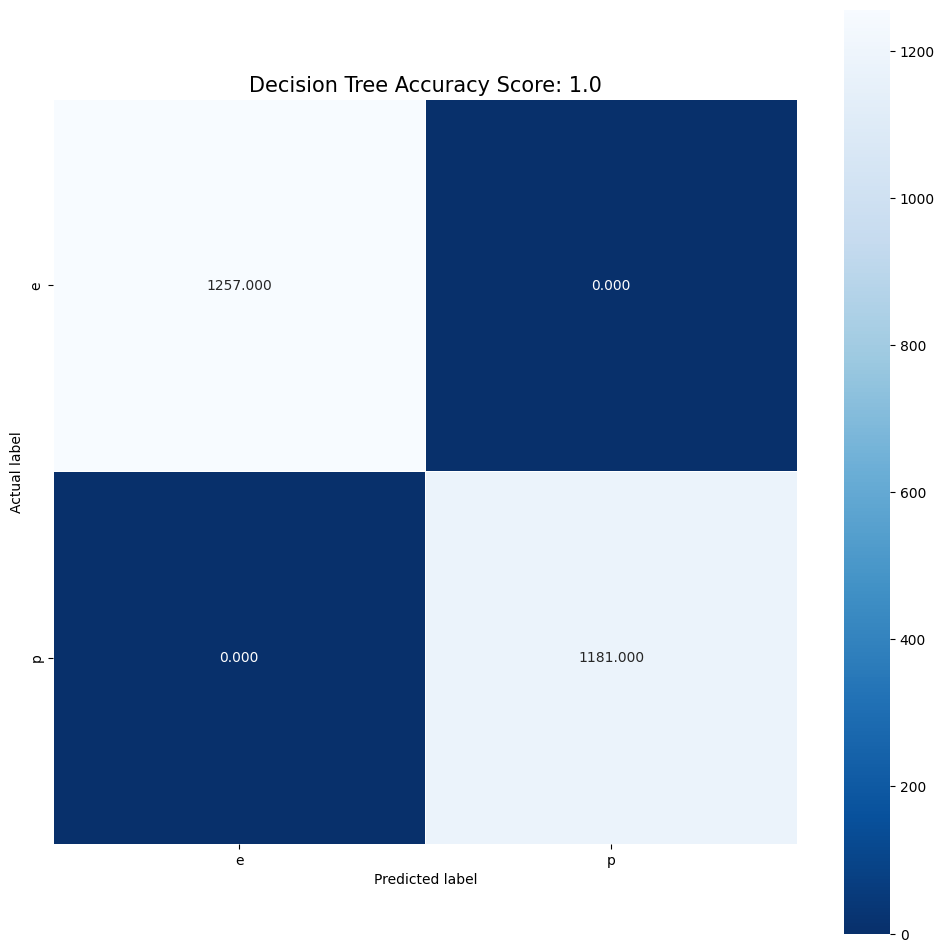

In [8]:
print(HO_TEN, "-", MSSV)

tree_cm = metrics.confusion_matrix(y_test, tree_pred)

plt.figure(figsize=(12,12))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf.classes_, yticklabels=clf.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Decision Tree Accuracy Score: {0}'.format(tree_score)
plt.title(title, size=15);

Nguyễn Gia Huy - 6451071027


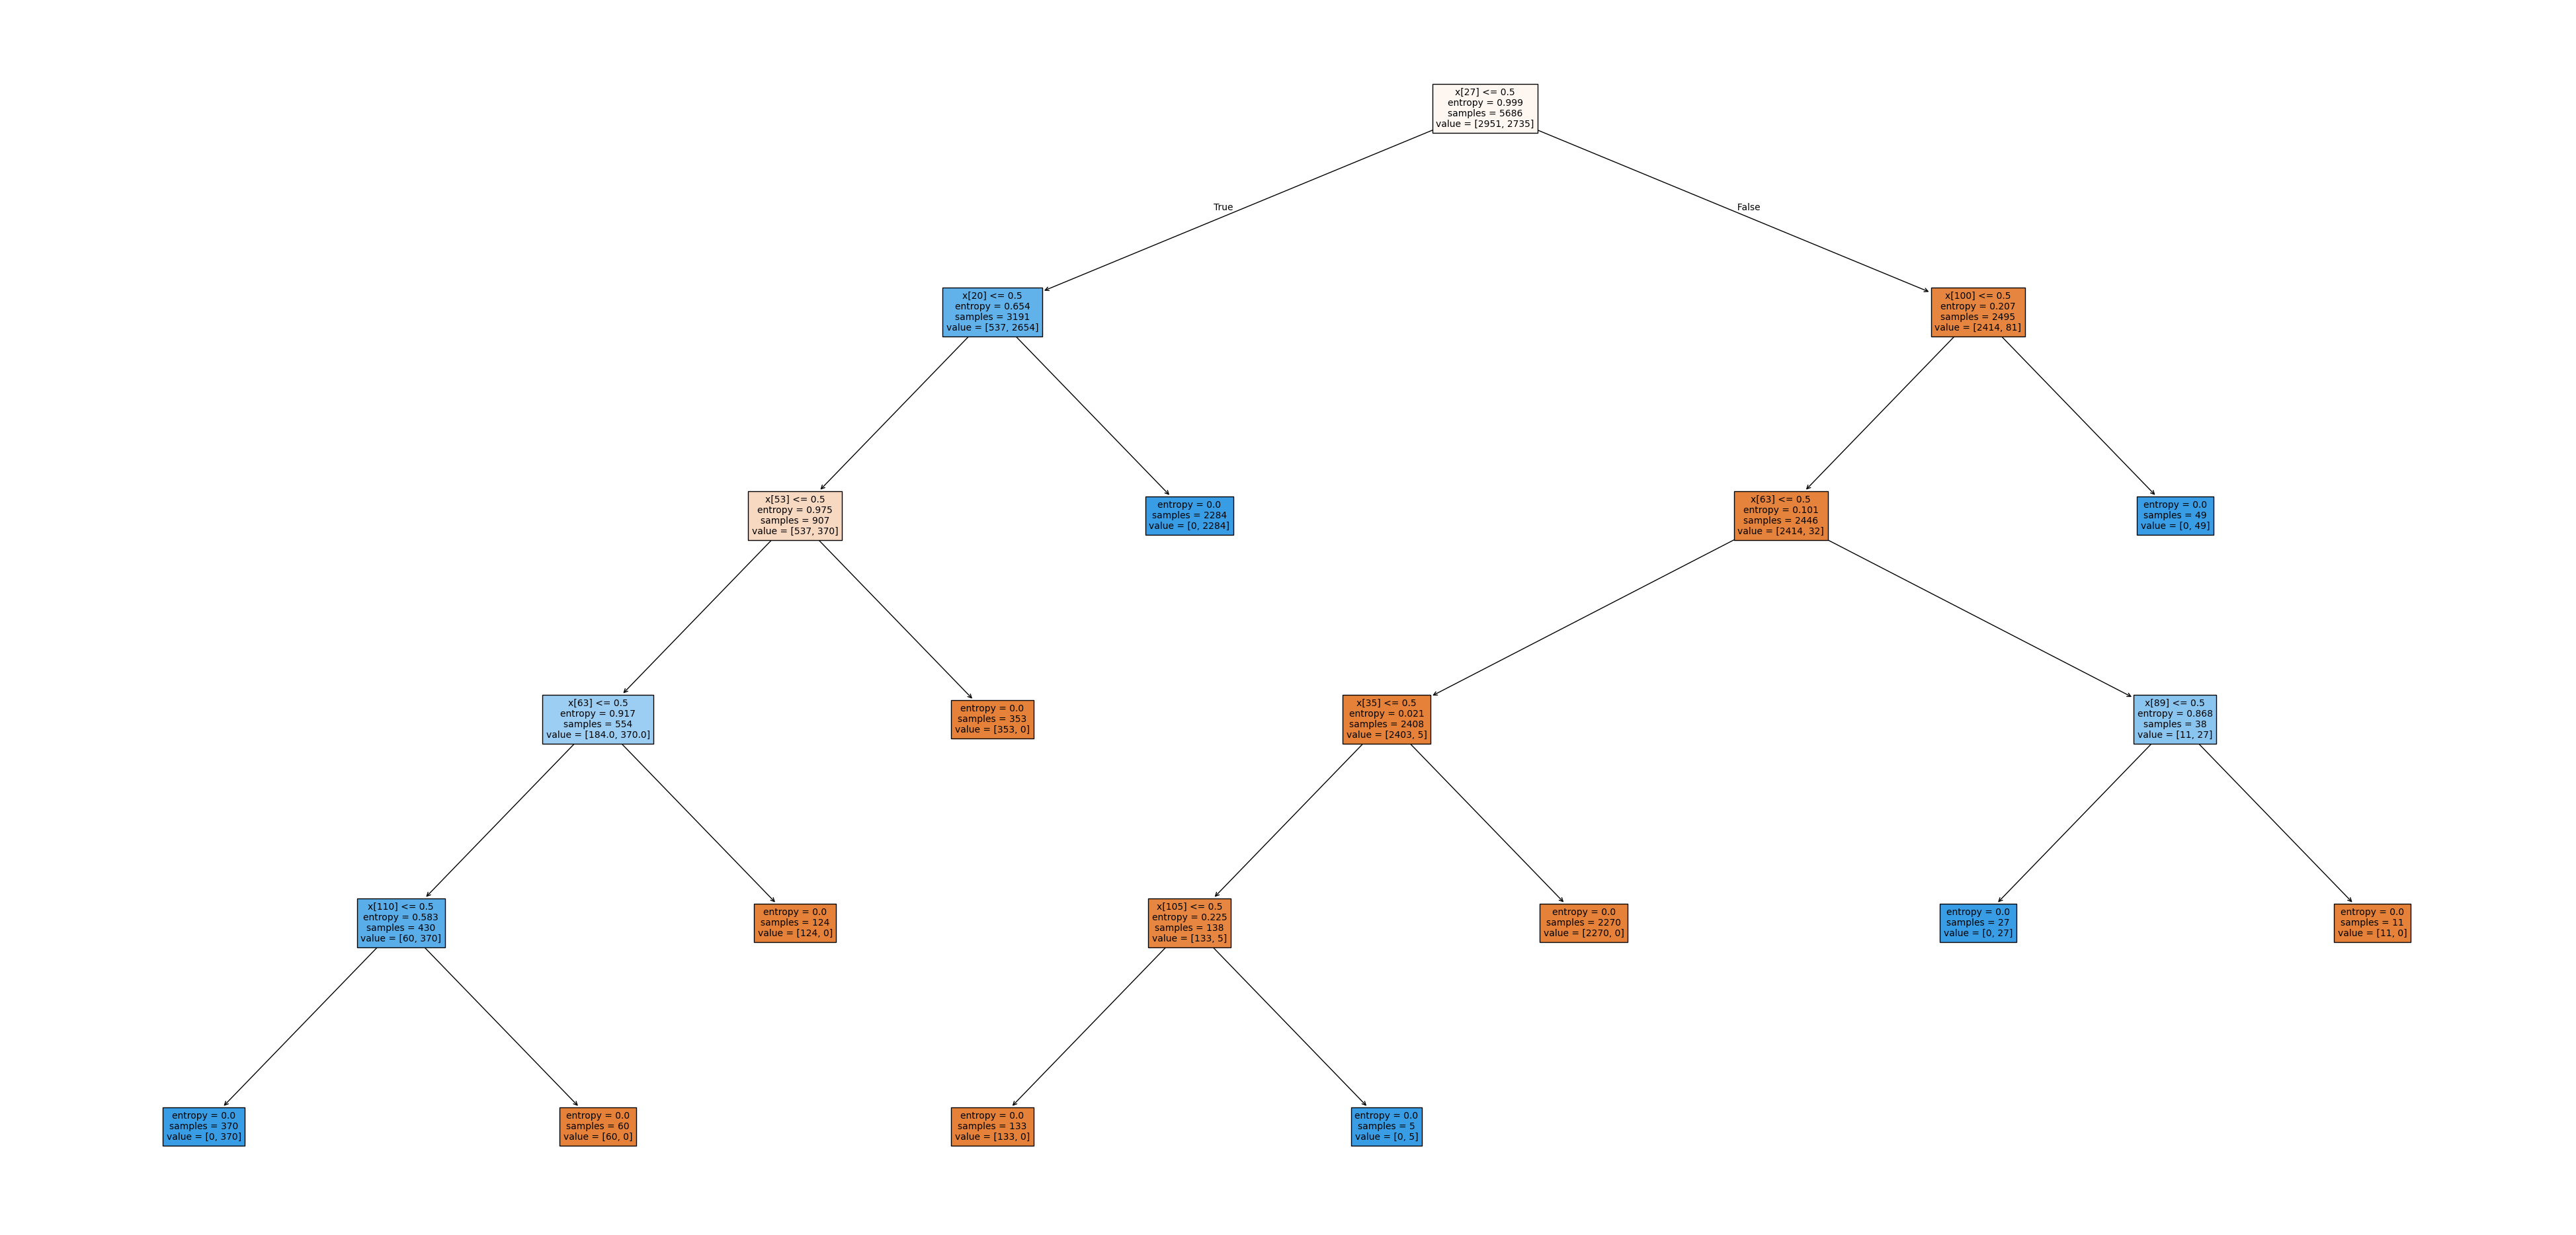

In [9]:
print(HO_TEN, "-", MSSV)

fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf, filled=True, fontsize=10)
plt.savefig('decision_tree', dpi=100)
plt.show()

## Câu 8: Xây dựng cây CART (criterion='gini')

In [10]:
print(HO_TEN, "-", MSSV)

clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
#Train Decision Tree Classifer
clf_cart.fit(X_train, y_train)

Nguyễn Gia Huy - 6451071027


DecisionTreeClassifier(random_state=0)

In [11]:
print(HO_TEN, "-", MSSV)

#Predict the response for test dataset
cart_pred = clf_cart.predict(X_test)

# Model Accuracy, how often is the classifier correct?
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:", metrics.classification_report(y_test, cart_pred, zero_division=0))

Nguyễn Gia Huy - 6451071027
Accuracy: 1.0
Report:               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



Nguyễn Gia Huy - 6451071027


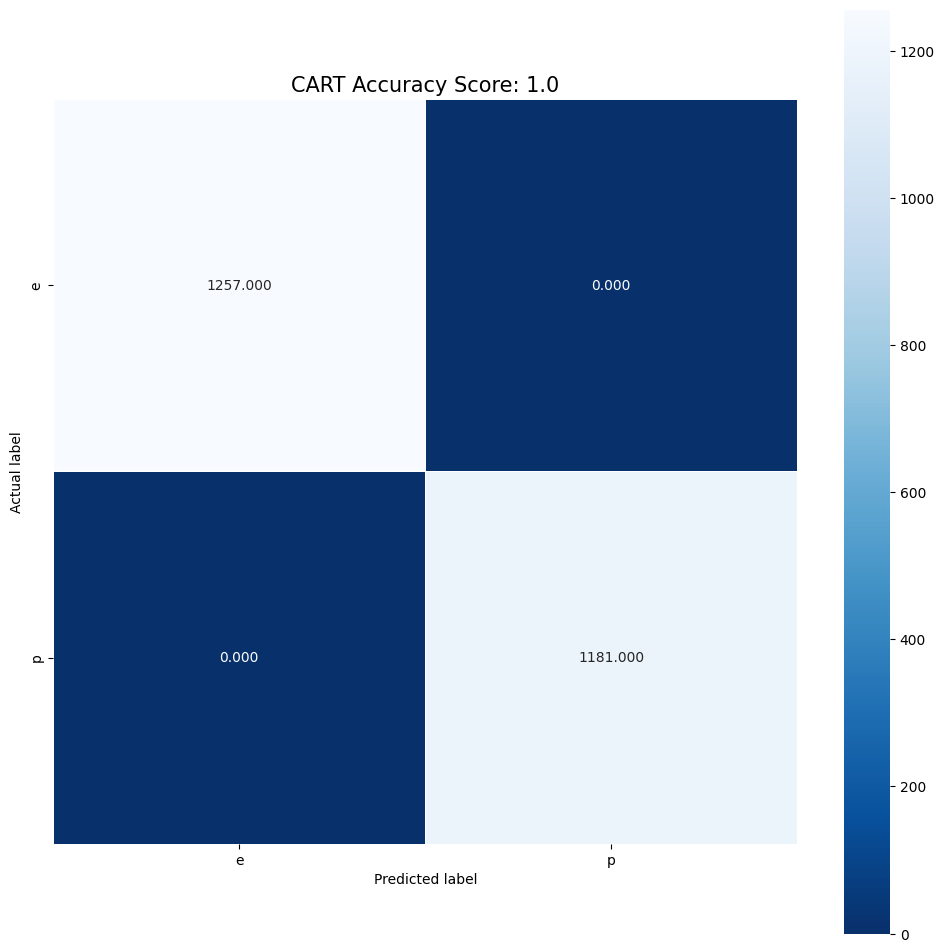

In [12]:
print(HO_TEN, "-", MSSV)

cart_cm = metrics.confusion_matrix(y_test, cart_pred)

plt.figure(figsize=(12,12))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'CART Accuracy Score: {0}'.format(cart_score)
plt.title(title, size=15);

Nguyễn Gia Huy - 6451071027


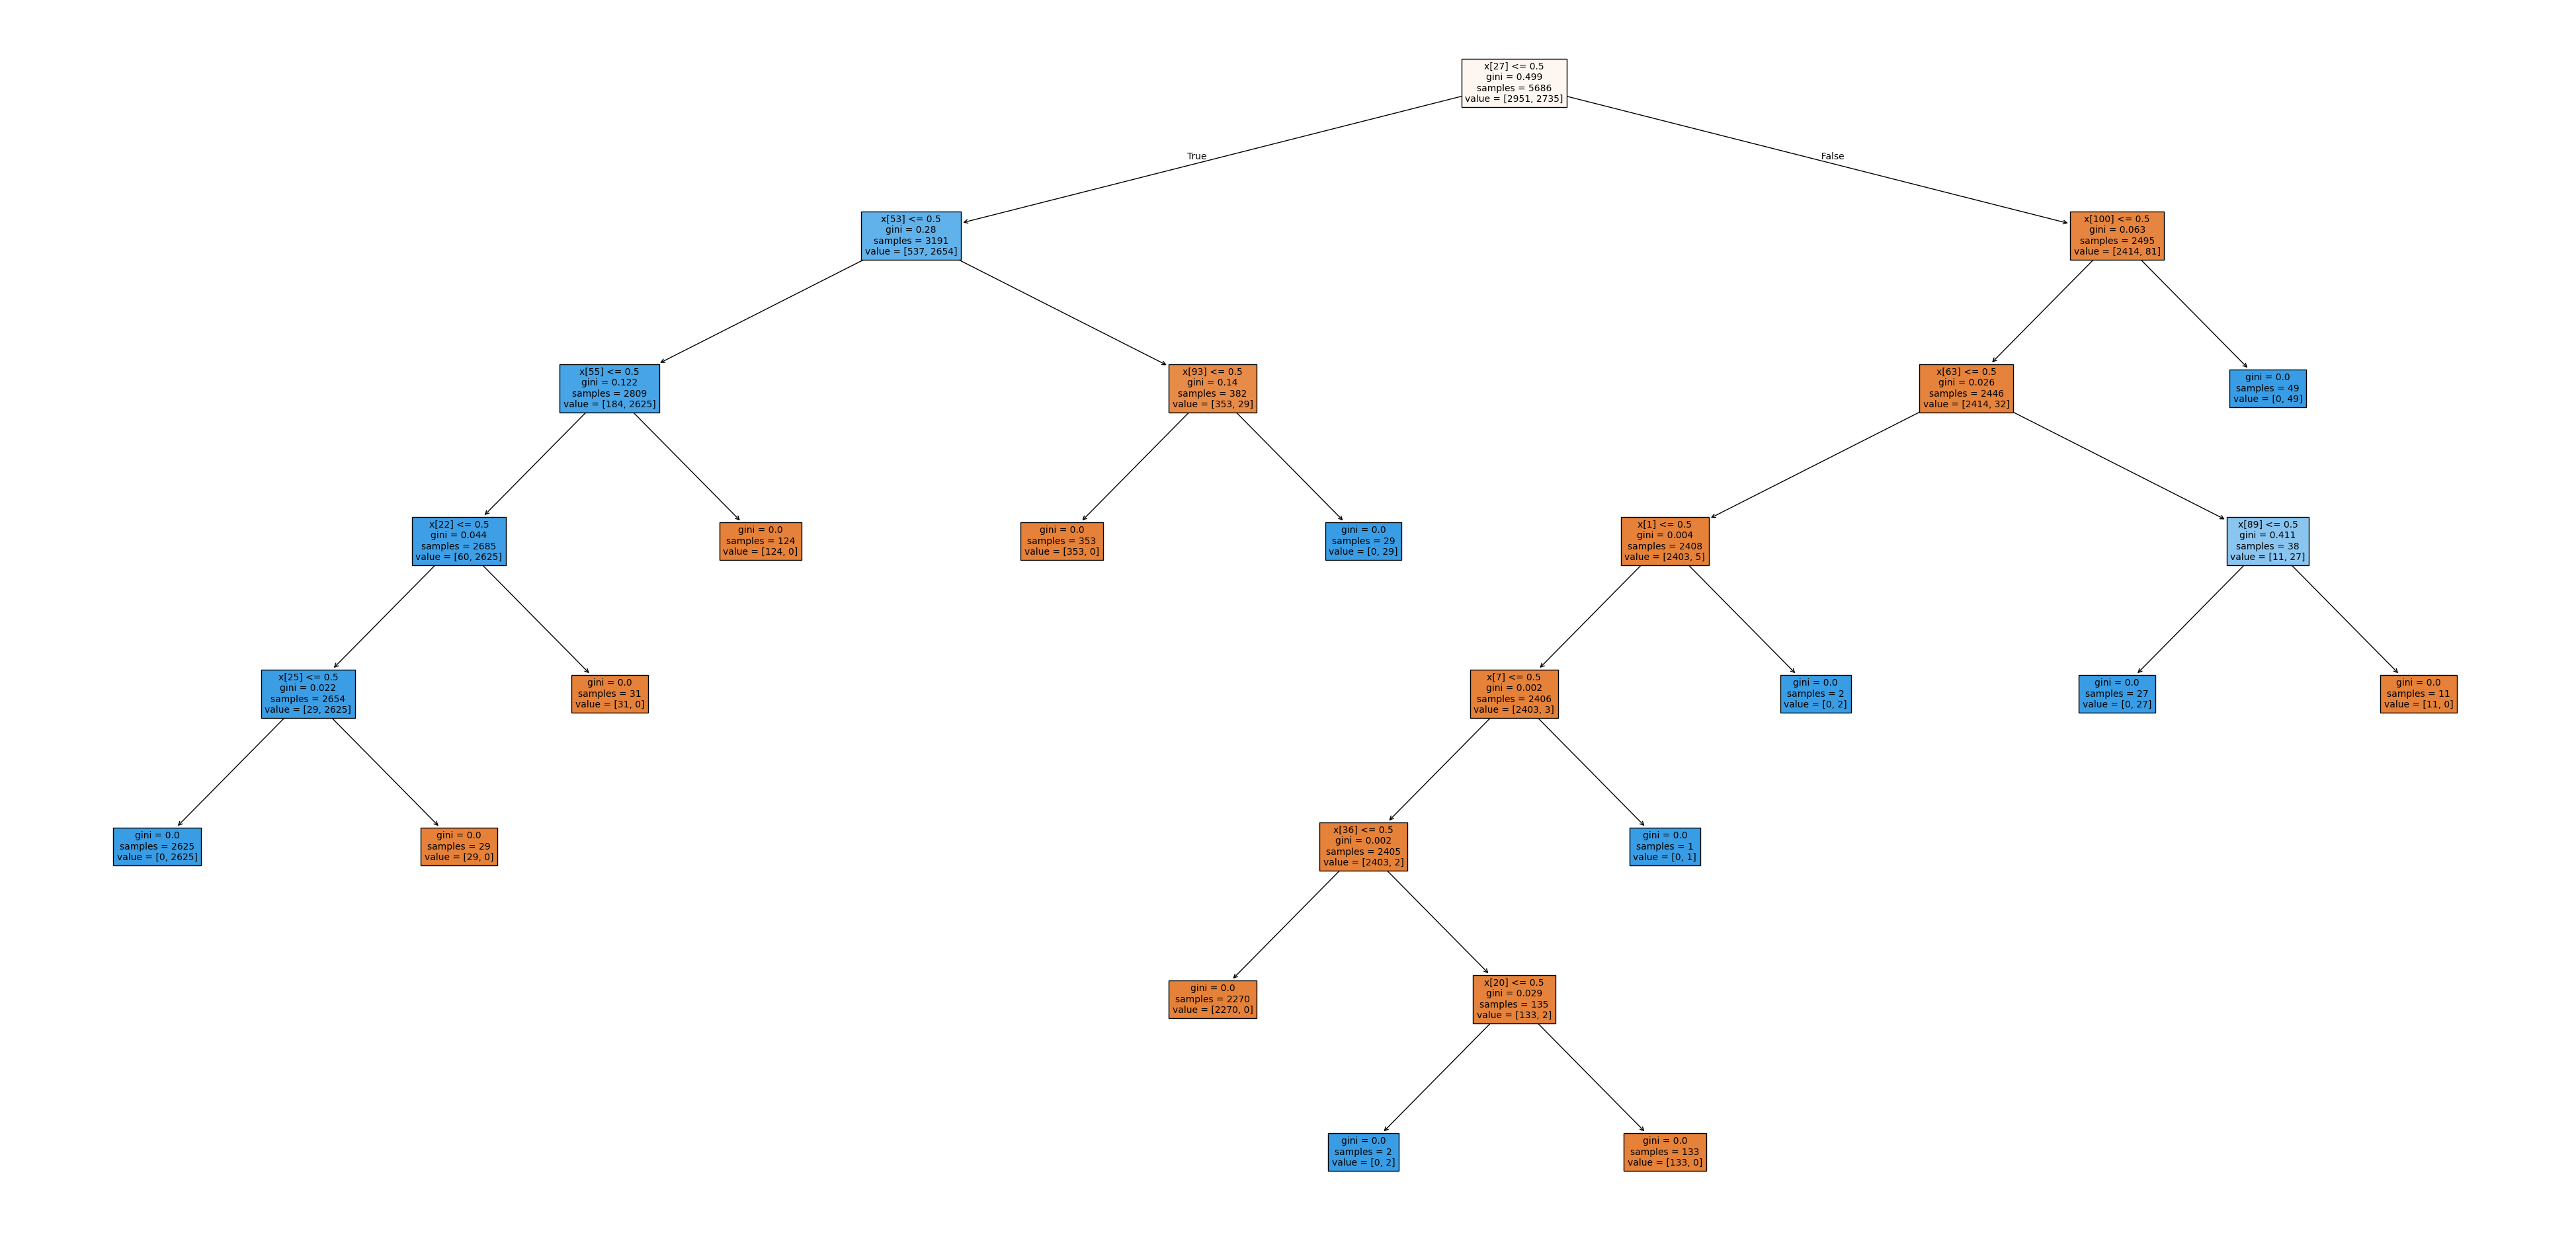

In [13]:
print(HO_TEN, "-", MSSV)

fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_cart, filled=True, fontsize=10)
plt.savefig('decision_tree_cart', dpi=100)
plt.show()

## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes

In [14]:
print(HO_TEN, "-", MSSV)

gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Nguyễn Gia Huy - 6451071027


In [15]:
print(HO_TEN, "-", MSSV)

# Model Accuracy, how often is the classifier correct?
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred, zero_division=0))

Nguyễn Gia Huy - 6451071027
Accuracy: 0.9643150123051681
Report:               precision    recall  f1-score   support

           e       1.00      0.93      0.96      1257
           p       0.93      1.00      0.96      1181

    accuracy                           0.96      2438
   macro avg       0.97      0.97      0.96      2438
weighted avg       0.97      0.96      0.96      2438



Nguyễn Gia Huy - 6451071027


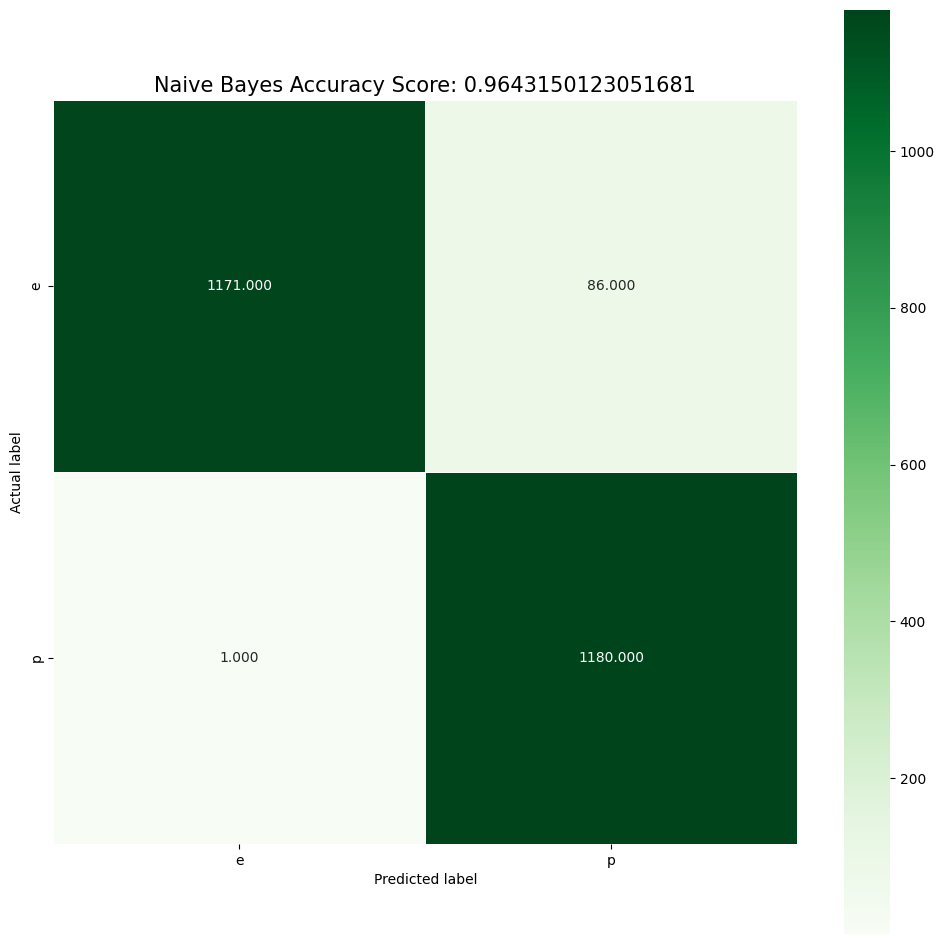

In [16]:
print(HO_TEN, "-", MSSV)

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

plt.figure(figsize=(12,12))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Naive Bayes Accuracy Score: {0}'.format(bayes_score)
plt.title(title, size=15);

## Câu 10: So sánh kết quả của các mô hình

In [17]:
print(HO_TEN, "-", MSSV)

ket_qua = {'ID3': tree_pred, 'CART': cart_pred, 'Naive Bayes': bayes_pred}
bang = pd.DataFrame({
    ten: {
        'Accuracy': metrics.accuracy_score(y_test, pred),
        'Precision (macro avg)': metrics.precision_score(y_test, pred, average='macro', zero_division=0),
        'Recall (macro avg)': metrics.recall_score(y_test, pred, average='macro', zero_division=0),
        'F1-score (macro avg)': metrics.f1_score(y_test, pred, average='macro', zero_division=0),
        'Precision (weighted avg)': metrics.precision_score(y_test, pred, average='weighted', zero_division=0),
        'Recall (weighted avg)': metrics.recall_score(y_test, pred, average='weighted', zero_division=0),
        'F1-score (weighted avg)': metrics.f1_score(y_test, pred, average='weighted', zero_division=0),
    } for ten, pred in ket_qua.items()
}).round(4)
bang

Nguyễn Gia Huy - 6451071027


,ID3,CART,Naive Bayes
Accuracy,1.0,1.0,0.9643
Precision (macro avg),1.0,1.0,0.9656
Recall (macro avg),1.0,1.0,0.9654
F1-score (macro avg),1.0,1.0,0.9643
Precision (weighted avg),1.0,1.0,0.9667
Recall (weighted avg),1.0,1.0,0.9643
F1-score (weighted avg),1.0,1.0,0.9643


Nguyễn Gia Huy - 6451071027


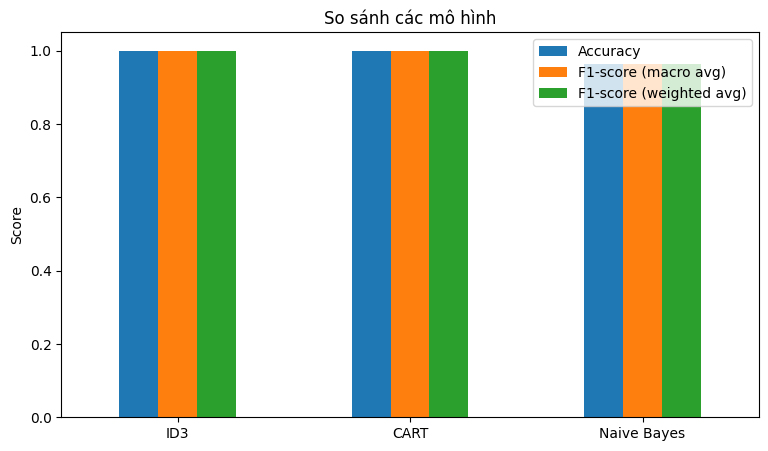

In [18]:
print(HO_TEN, "-", MSSV)

bang.T[['Accuracy', 'F1-score (macro avg)', 'F1-score (weighted avg)']].plot(kind='bar', figsize=(9, 5), rot=0)
plt.title('So sánh các mô hình')
plt.ylabel('Score')
plt.show()